# WQF7009 Assignment 1: Using SHAP for Stroke Prediction Model
## Part 2: Logistic Regression

Author: Gan Yee Jing (25102061)

Creation Date: 2026-11-02

Trains a logistic regression on the cleaned train/test files exported from `01_eda.ipynb`, then explains it with SHAP: the explainer (Task 2), local explanations with force plots (Task 3) and the global explanation with a summary plot (Task 4).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, average_precision_score, RocCurveDisplay)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")

c:\Users\hp\Downloads\Master\02_Sem1\WQF7009 - Explainable Artificial Intelligence (XAI)\WQF7009---Assignment-1\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### a) Load data

In [2]:
train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")

target = "stroke"
X_train, y_train = train.drop(columns=["id", target]), train[target]
X_test, y_test = test.drop(columns=["id", target]), test[target]

print(f"Train: {X_train.shape}, stroke rate {y_train.mean():.2%}")
print(f"Test:  {X_test.shape}, stroke rate {y_test.mean():.2%}")
X_train.head()

Train: (4087, 11), stroke rate 4.87%
Test:  (1022, 11), stroke rate 4.89%


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,bmi_missing
0,Female,48.0,0,0,Yes,Private,Urban,69.21,33.1,never smoked,0
1,Female,29.0,0,0,No,Private,Urban,84.19,21.2,never smoked,0
2,Female,35.0,0,0,Yes,Private,Rural,119.40,22.9,never smoked,0
3,Male,38.0,0,0,Yes,Private,Rural,108.68,32.7,never smoked,0
4,Male,14.0,0,0,No,Govt_job,Urban,82.34,31.6,Unknown,0


### b) Preprocessing and model
| Feature type | Columns | Encoding |
|---|---|---|
| Numeric | `age`, `avg_glucose_level`, `bmi` | Standardised (fitted on train) |
| Categorical | `gender`, `ever_married`, `work_type`, `Residence_type`, `smoking_status` | One-hot, first category dropped |
| Boolean | `hypertension`, `heart_disease`, `bmi_missing` | Unchanged |

`class_weight="balanced"` handles the class imbalance (~4.9% stroke) by giving stroke cases more weight.

In [3]:
num_cols = ["age", "avg_glucose_level", "bmi"]
cat_cols = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]
bin_cols = ["hypertension", "heart_disease", "bmi_missing"]

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
    ("bin", "passthrough", bin_cols),
], verbose_feature_names_out=False)

model = Pipeline([
    ("preprocess", preprocess),
    ("lr", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)),
])
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('lr', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['gender','age','hypertension',...,'bmi','smoking_status','bmi_missing']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `

### c) Evaluation

In [4]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print(f"ROC AUC: {roc_auc_score(y_test, y_prob):.3f}")
print(f"PR AUC:  {average_precision_score(y_test, y_prob):.3f} (baseline {y_test.mean():.3f})")
print()
print(classification_report(y_test, y_pred, target_names=["No stroke", "Stroke"]))

ROC AUC: 0.837
PR AUC:  0.227 (baseline 0.049)

              precision    recall  f1-score   support

   No stroke       0.99      0.75      0.85       972
      Stroke       0.14      0.80      0.24        50

    accuracy                           0.75      1022
   macro avg       0.56      0.78      0.55      1022
weighted avg       0.95      0.75      0.82      1022



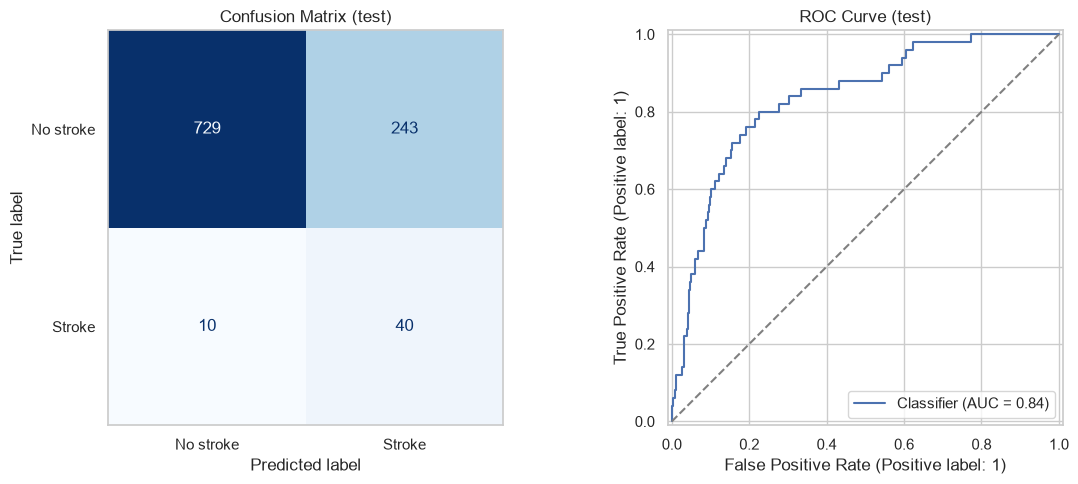

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["No stroke", "Stroke"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion Matrix (test)")
axes[0].grid(False)
RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[1])
axes[1].plot([0, 1], [0, 1], ls="--", color="grey")
axes[1].set_title("ROC Curve (test)")
plt.tight_layout()
plt.show()

### d) Task 2: SHAP explainer
- `shap.LinearExplainer` is used because the model is linear; it computes exact SHAP values quickly.
- The training set is the background data, so each explanation is relative to an average training patient.
- For a linear model, a feature's SHAP value = coefficient × (patient's value − average value), in log-odds.
- Base value = the model's average output (log-odds). Base value + sum of SHAP values = the patient's prediction.
- Numeric features are shown in their original units (e.g. age in years) instead of standardised values, so the plots are easier to read.

In [6]:
# Transform the data the same way the model sees it
feature_names = model.named_steps["preprocess"].get_feature_names_out()
X_train_t = pd.DataFrame(model.named_steps["preprocess"].transform(X_train), columns=feature_names, index=X_train.index)
X_test_t = pd.DataFrame(model.named_steps["preprocess"].transform(X_test), columns=feature_names, index=X_test.index)

# Create the explainer with the full training set as background, then explain the test set
masker = shap.maskers.Independent(X_train_t, max_samples=len(X_train_t))
explainer = shap.LinearExplainer(model.named_steps["lr"], masker)
shap_values = explainer(X_test_t)

# Show numeric features in original units in the plots (SHAP values are unchanged)
X_test_display = X_test_t.copy()
X_test_display[num_cols] = X_test[num_cols].values
shap_values.data = X_test_display.round(2).values

base = explainer.expected_value
print(f"Base value: {base:.3f} log-odds (probability {1 / (1 + np.exp(-base)):.3f})")

# Check: base value + sum of SHAP values = model output
diff = np.abs(base + shap_values.values.sum(axis=1) - model.decision_function(X_test)).max()
print(f"Max difference from model output: {diff:.2e}")

Base value: -1.258 log-odds (probability 0.221)
Max difference from model output: 1.33e-15


### e) Task 3: Local explanation (force plot)
Explains individual patients. Two test patients are shown: the stroke patient with the highest predicted risk and the non-stroke patient with the lowest.

**How to read the force plot**
- The scale is log-odds. `base value` is the average prediction; `f(x)` is this patient's prediction.
- Red features push the risk up; blue features push it down. Wider arrows mean a bigger effect.
- Only features with a noticeable contribution are labelled.

Highest-risk stroke patient | id 8213 | actual stroke: 1 | predicted probability: 0.970


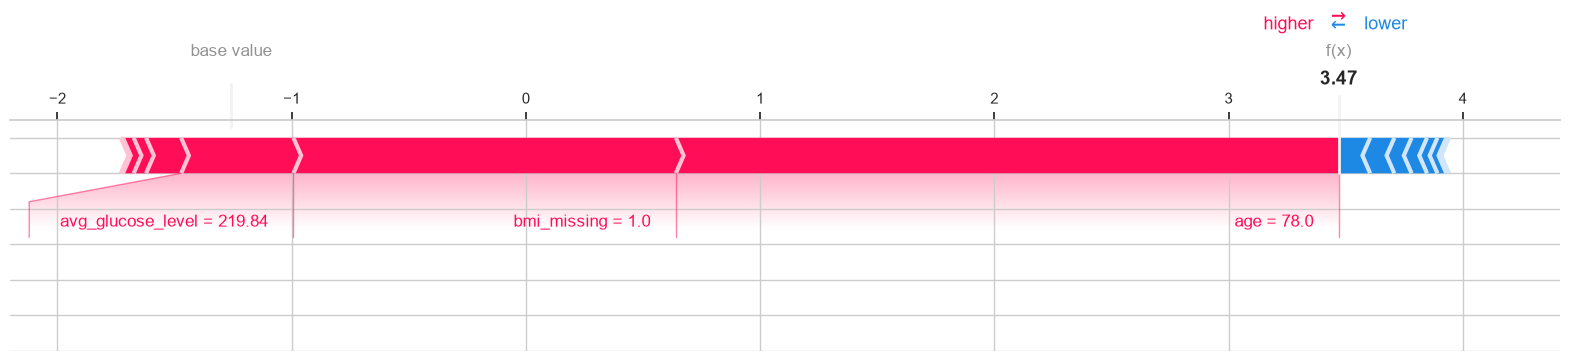

Lowest-risk non-stroke patient | id 54975 | actual stroke: 0 | predicted probability: 0.005


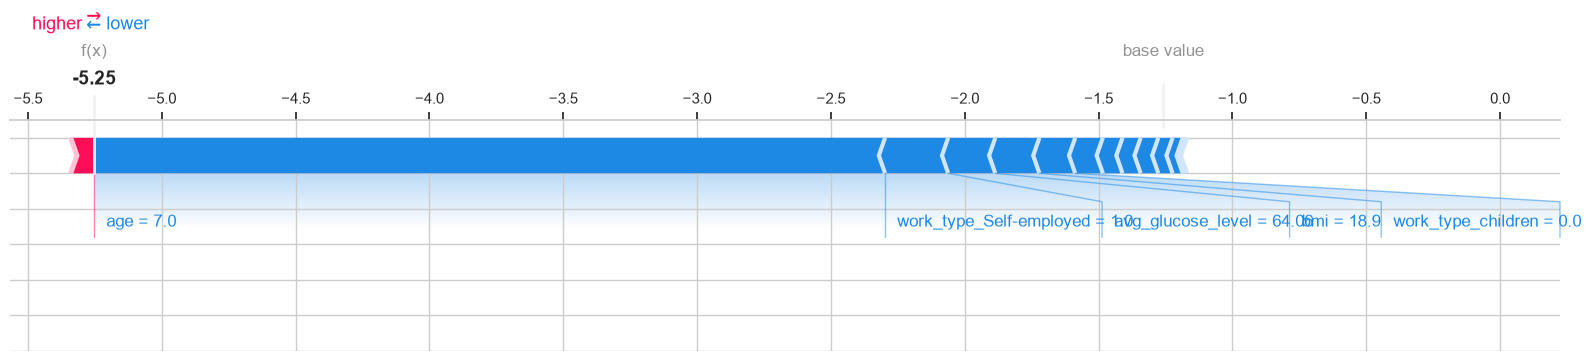

In [7]:
def plot_force(i, title):
    """Force plot for the i-th test patient."""
    print(f"{title} | id {test['id'].iloc[i]} | actual stroke: {y_test.iloc[i]} | predicted probability: {y_prob[i]:.3f}")
    shap.plots.force(shap_values[i], matplotlib=True, figsize=(20, 3), contribution_threshold=0.1)


i_high = int(np.argmax(np.where(y_test == 1, y_prob, -1)))
i_low = int(np.argmin(np.where(y_test == 0, y_prob, 2)))

plot_force(i_high, "Highest-risk stroke patient")
plot_force(i_low, "Lowest-risk non-stroke patient")

### f) Task 4: Global explanation (summary plot)
Combines the SHAP values of all test patients to show which features matter most overall.

**How to read the summary (beeswarm) plot**
- Features are ranked from most to least important (mean |SHAP value|).
- Each dot is one patient. Its position shows how much that feature pushed the prediction up (right) or down (left).
- Colour shows the feature value: red = high, blue = low. For example, red dots on the right mean high values raise the risk.

The bar plot shows the same ranking as a single number per feature (mean |SHAP value|).

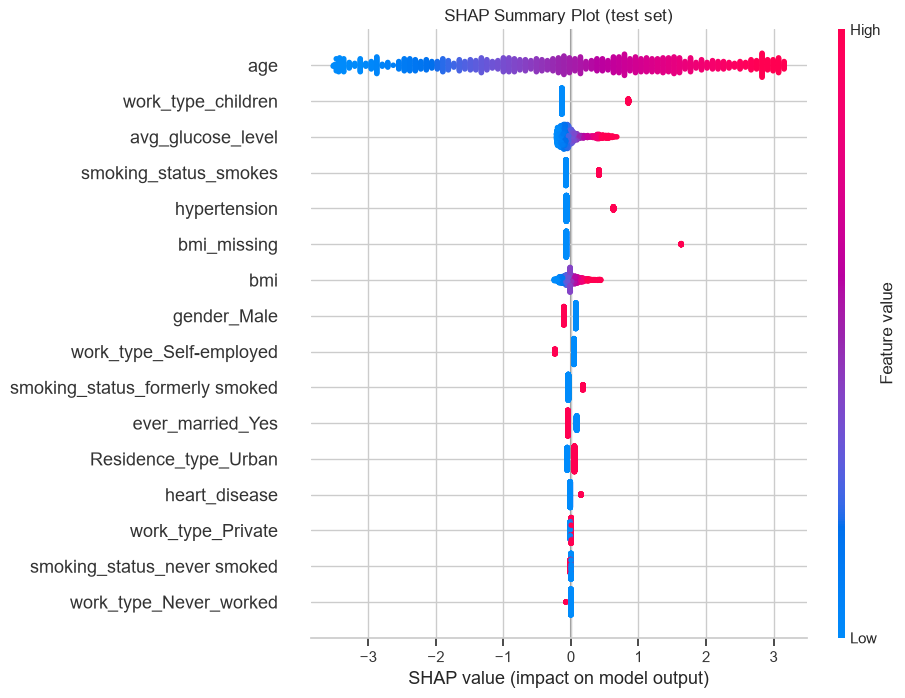

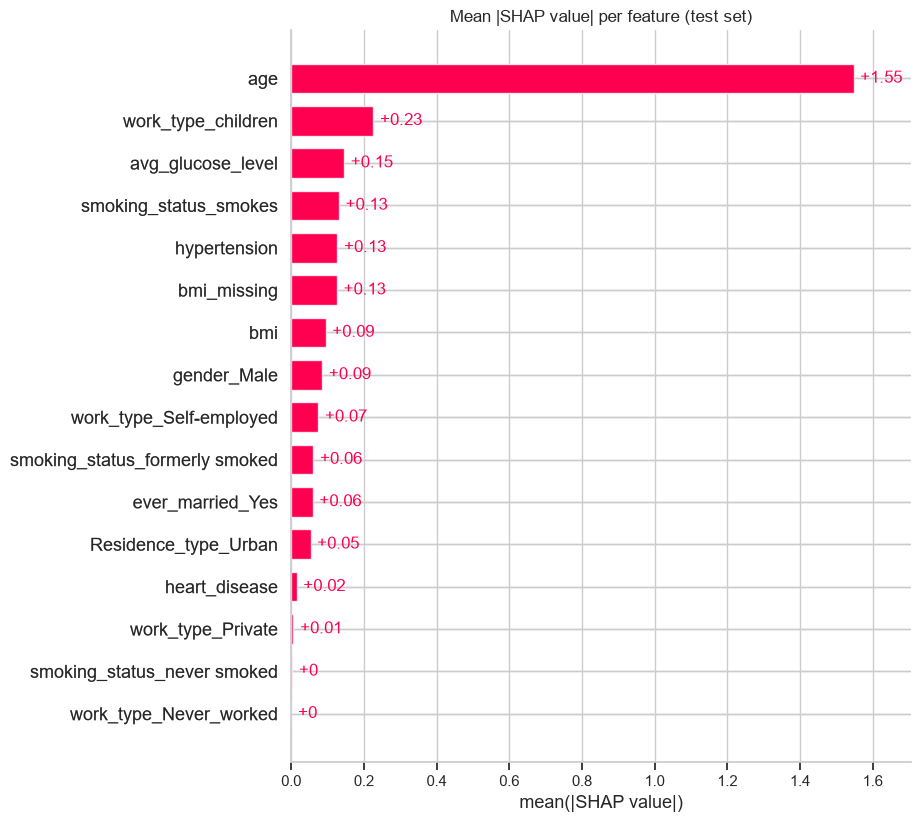

In [8]:
shap.plots.beeswarm(shap_values, max_display=len(feature_names), show=False)
plt.title("SHAP Summary Plot (test set)")
plt.show()

shap.plots.bar(shap_values, max_display=len(feature_names), show=False)
plt.title("Mean |SHAP value| per feature (test set)")
plt.show()